<a href="https://colab.research.google.com/github/brais-muino-otero/HackUDC_2026/blob/main/es/lab9/lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab9/lab9.ipynb)

# Práctica 9: RNNs

## Pre-requisitos
En esta práctica utilizaremos los paquetes `pandas` y `seaborn` para examinar y manipular los datos.

In [1]:
# Hacemos los imports que sean necesarios
import numpy as np               # Librería para cálculo numérico y manejo de arrays multidimensionales
import matplotlib.pyplot as plt  # Módulo para la creación de gráficos y visualización de datos
import pandas as pd              # Librería para manipulación y análisis de datos mediante dataframes
import seaborn as sns            # Librería de visualización de datos estadísticos basada en matplotlib


# Pronóstico de series de tiempo

Vamos a utilizar un [conjunto de datos de series de tiempo meteorológicas](https://www.bgc-jena.mpg.de/wetter/) registradas por el Instituto Max Planck de Biogeoquímica.

Este conjunto de datos contiene 14 características diferentes, como la temperatura del aire, la presión atmosférica y la humedad. Estos se recopilaron cada 10 minutos, de 2009 a 2016.

Lo primero que vamos a hacer es cargar los datos en un DataFrame de la librería [Pandas](https://pandas.pydata.org/).

## Carga de los datos
En la siguiente celda descargaremos los datos y los cargaremos en un `DataFrame` de `pandas`.

In [2]:
import urllib.request                                                                                                        # Módulo estándar para abrir y descargar URLs de internet

print('Downloading...')                                                                                                     # Muestra un mensaje en pantalla indicando el inicio de la descarga
urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip', 'jena_climate_2009_2016.csv.zip') # Descarga el archivo zip desde la URL y lo guarda en el disco local
print("Download complete! Unzipping...")                                                                                    # Muestra un mensaje indicando que la descarga terminó y comenzará la descompresión

import zipfile                                                                                                              # Módulo estándar para manipular y descomprimir archivos en formato ZIP
with zipfile.ZipFile("jena_climate_2009_2016.csv.zip", "r") as zip_ref:                                                      # Abre de forma segura el archivo ZIP descargado en modo lectura ('r')
    zip_ref.extractall("./")                                                                                                # Extrae todos los contenidos del archivo ZIP en el directorio actual
print("Your data is ready!")                                                                                                # Muestra un mensaje indicando que los datos se han extraído correctamente

df = pd.read_csv("jena_climate_2009_2016.csv")[::6]                                                                          # Lee el CSV extraído y toma una de cada 6 filas (muestreo cada hora, en lugar de cada 10 min)

Downloading...
Download complete! Unzipping...
Your data is ready!


## Visualización de los datos

Antes de nada, vamos a echar un vistazo a los datos.

In [8]:
df.head() # Muestra las primeras 5 filas del DataFrame para tener una vista rápida de los datos iniciales

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
6,01.01.2009 01:10:00,996.50,-7.62,265.81,-8.30,94.8,3.44,3.26,0.18,2.04,3.27,1305.68,0.18,0.63,166.5
12,01.01.2009 02:10:00,996.63,-8.85,264.57,-9.70,93.5,3.12,2.92,0.20,1.82,2.93,1312.11,0.16,0.50,158.3
18,01.01.2009 03:10:00,996.87,-8.84,264.56,-9.69,93.5,3.13,2.92,0.20,1.83,2.93,1312.37,0.07,0.25,129.3
24,01.01.2009 04:10:00,997.05,-9.23,264.15,-10.25,92.2,3.03,2.79,0.24,1.74,2.80,1314.62,0.10,0.38,203.9


También podemos ver como cambian los datos de las variables a lo largo del tiempo

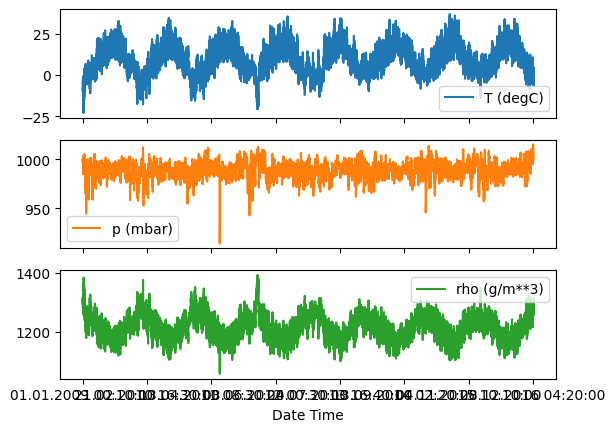

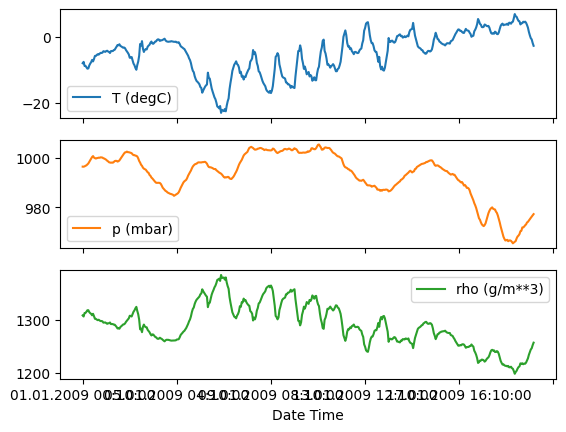

In [5]:
plot_cols = ['T (degC)', 'p (mbar)', 'rho (g/m**3)']                      # Definimos las columnas específicas que queremos graficar
plot_features = df[plot_cols]                                                # Seleccionamos únicamente esas columnas del DataFrame original
plot_features.index = df['Date Time']                                        # Asignamos la columna de fecha y hora como el índice para el eje X
_ = plot_features.plot(subplots=True)                                        # Graficamos cada variable en un gráfico independiente (subplots)

plot_features = df[plot_cols][:480]                                          # Filtramos las primeras 480 filas para visualizar un periodo más corto
plot_features.index = df['Date Time'][:480]                                  # Asignamos las fechas correspondientes a este periodo corto como índice
_ = plot_features.plot(subplots=True)                                        # Graficamos el periodo recortado en subplots individuales

## Preprocesado de los datos

Primero de nada, vamos a observar las estadísticas de cada dato. Para ello, la librería Pandas nos permite obtener información de una manera muy sencilla.

In [9]:
df.describe().transpose() # Genera estadísticas descriptivas resumidas (media, desviación, mínimos, máximos) de cada columna y las transpone para leerlas mejor

,count,mean,std,min,25%,50%,75%,max
p (mbar),70092.0,989.212830,8.358709,914.10,984.20,989.58,994.72,1015.28
T (degC),70092.0,9.450272,8.423862,-23.01,3.36,9.42,15.47,37.13
Tpot (K),70092.0,283.492874,8.504928,250.60,277.43,283.47,289.53,311.06
Tdew (degC),70092.0,4.955267,6.730338,-25.01,0.23,5.22,10.06,23.11
rh (%),70092.0,76.005225,16.477654,14.20,65.21,79.30,89.40,100.00
VPmax (mbar),70092.0,13.576563,7.739742,0.95,7.78,11.82,17.60,63.26
VPact (mbar),70092.0,9.533275,4.183679,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),70092.0,4.043228,4.898197,0.00,0.87,2.19,5.30,45.42
sh (g/kg),70092.0,6.022089,2.655839,0.50,3.92,5.59,7.80,18.13
H2OC (mmol/mol),70092.0,9.639723,4.234911,0.80,6.28,8.96,12.48,28.82


### Limpiar el dataset
En los datos podemos ver cosas extrañas. Por ejemplo, en la velocidad **wv** tenemos, como dato mínimo, valores de -9999m/s, que es una velocidad absurda. En este caso tenemos dos opciones:

1. Eliminar las filas con el error.
1. Poner un dato más fiable.

En nuestro caso, vamos a decidirnos por la última, sustituyendo cualquier valor menor que 0 por un 0.


In [10]:
# TODO: sustituye los datos negativos de las columnas wv (m/s) y max. wv (m/s) por 0's
wv = df['wv (m/s)']          # Extraemos la columna de la velocidad del viento para poder manipularla
wv_negativos = None          # PISTA: Crea una máscara booleana que detecte qué valores de 'wv' son menores que cero
wv[wv_negativos] = None      # Usa la máscara anterior para indexar y asignar el valor 0 a esos registros negativos

wv_max = None                # PISTA: Extrae la columna 'max. wv (m/s)' de manera análoga
None                         # PISTA: Crea la máscara booleana para identificar los valores negativos de la ráfaga máxima
None                         # PISTA: Sustituye esos valores negativos por 0 en la columna de ráfaga máxima

Si la operación se ha completado satisfactoriamente, puedes volver a evaluar las estadísticas del dataset para comprobar que se han modificado los valores.

### Transformación de datos

Si observamos los datos vemos que tenemos ciertos componentes que necesitan ser preprocesados para que la representación sea más adecuada para la red neuronal.

#### Viento

El viento se compone de las 3 últimas variables. En especial la última, **wd (deg)**, que marca la dirección del viento. ¿Cuál es el problema que contiene esta variable? Tómate un tiempo para evaluar la problemática.

<font color='red'>TODO:</font> Escribe aquí el motivo por el que crees que la variable **wd (deg)** puede ser problemática en su forma actual. <font color='red'>PISTA:</font> Piensa en cómo se codifican los vientos que apuntan cerca del norte.



¿Ya te has dado cuenta del problema? ¡Es hora de arreglarlo! Sustituye el dato por una representación más útil.

<font color='red'>PISTA:</font> la solución implica dividir la variable en dos nuevos campos que se corresponden con funciones trigonométricas.

In [13]:
# Convertimos los grados a radianes (comprobando primero si la columna existe en el DataFrame para evitar KeyErrors)
if 'wd (deg)' in df.columns:
    wd_rad = df.pop('wd (deg)')*np.pi / 180  # Extrae la columna en grados y la convierte a radianes

# TODO: modifica wd (deg) para obtener una mejor representación
# Crea los nuevos componentes e insértalos en el dataframe.
df['Wx'] = df['wv (m/s)'] * np.cos(wd_rad)           # Calcula la componente X del viento usando el coseno y la velocidad
df['Wy'] = df['wv (m/s)'] * np.sin(wd_rad)           # Calcula la componente Y del viento usando el seno y la velocidad

df['max Wx'] = df['max. wv (m/s)'] * np.cos(wd_rad)   # Calcula la componente X de la ráfaga máxima usando su velocidad máxima
df['max Wy'] = df['max. wv (m/s)'] * np.sin(wd_rad)   # Calcula la componente Y de la ráfaga máxima usando su velocidad máxima

#### Fecha

La fecha es también algo muy importante en los datos, pero hay que tener en cuenta su periodicidad. En concreto, dos casos:

- Periodicidad en la hora del día.
- Periodicidad en la época del año.

Un método simple para convertirlo en una señal utilizable es usar el [seno](https://numpy.org/doc/stable/reference/generated/numpy.sin.html) y el [coseno](https://numpy.org/doc/stable/reference/generated/numpy.cos.html) para convertir la hora en señales claras de "Hora del día" y "Hora del año". Hay que operar de tal manera que:

1. $\cos(hora~0) = \cos(hora~24)$ y $\sin(hora~0) = \sin(hora~24)$ en la hora del día.
1. $\cos(1~enero) \approx \cos(31~diciembre)$ y $\sin(1~enero) \approx \sin(31~diciembre)$ en la hora anual.

<font color='red'>PISTA:</font> recuerda que:
- $\cos(0) = \cos(2\pi)$.
- $\sin(0) = \sin(2\pi)$.

In [16]:
# Vamos a quitar la columna de la fecha comprobando si existe para evitar KeyErrors en re-ejecuciones
if 'Date Time' in df.columns:
    date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')  # Convierte la columna de fecha a objetos Datetime y la extrae

# Lo convertimos en segundos
timestamp_s = date_time.map(pd.Timestamp.timestamp)                         # Mapea cada fecha a su representación numérica en segundos epoch

# TODO: calcula el número de segundos de un día y de un año
day = 24 * 60 * 60                                                          # Calcula los segundos de un día: 24 horas * 60 minutos * 60 segundos
year = day * 365.2425                                                       # Calcula los segundos de un año considerando los años bisiestos (365.2425 días)

# TODO: Extrae, para cada fecha, el seno y el coseno, y añádelos al dataframe
df['Dia sin'] = np.sin(timestamp_s * (2 * np.pi / day))                     # Aplica la función seno para capturar la naturaleza cíclica diaria
df['Dia cos'] = np.cos(timestamp_s * (2 * np.pi / day))                     # Aplica la función coseno para capturar la naturaleza cíclica diaria
df['Anho sin'] = np.sin(timestamp_s * (2 * np.pi / year))                   # Aplica la función seno para capturar la naturaleza cíclica anual
df['Anho cos'] = np.cos(timestamp_s * (2 * np.pi / year))                   # Aplica la función coseno para capturar la naturaleza cíclica anual

## Partición de datos

Usaremos una división **(70%, 20%, 10%)** para los conjuntos de entrenamiento, validación y prueba. Tenga en cuenta que los datos **no** se mezclan aleatoriamente antes de dividirlos. Esto es por dos razones:

1. Garantiza que aún sea posible dividir los datos en ventanas de muestras consecutivas.
1. Garantiza que los resultados de la validación / prueba sean más realistas y se evalúen en función de los datos recopilados después de que el modelo haya sido entrenado.

In [17]:
# TODO: parte los datos según el porcentaje estipulado
n_datos = len(df)                                                                                                           # Obtiene el número total de filas del DataFrame para calcular los porcentajes

train_df = df[0:int(n_datos*0.7)]                                                                                           # Toma el primer 70% de los datos secuenciales para el conjunto de entrenamiento
val_df = df[int(n_datos*0.7):int(n_datos*0.9)]                                                                              # Toma el siguiente 20% de los datos (del 70% al 90%) para el conjunto de validación
test_df = df[int(n_datos*0.9):]                                                                                             # Toma el 10% restante de los datos (del 90% al final) para el conjunto de prueba

# Estandarización de los datos

Para que una red neuronal entrene correctamente suele ser necesario que todos los datos tengan una misma escala, o al menos una parecida. Sin embargo, anteriormente hemos visto como algunas variables tienen medias cercanas a 1000, mientras que otras rondan el 0. Por tanto, necesitamos igualarlas.

Existen múltiples maneras de escalar los datos, pero una de las más comunes es la estandarización:

$$ \tilde{x} = \dfrac{x - mean(x)}{std(x)} $$

Consiste en restar, **a cada columna**, su media, dividiendo el resultado por su desviación típica. Para realizarlo, podemos hacer uso de las funciones de Pandas [mean](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html) y [std](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.std.html).

Otra cosa a tener en cuenta es que **se usa la media y desviación del conjunto de entrenamiento** para normalizar todos los datos. Esto es así porque es el único conjunto de datos que conoceríamos a priori en un problema real.

In [18]:
# TODO = normaliza los dataframes
train_mean = train_df.mean()                                                                                                # Calcula la media de cada columna utilizando únicamente el conjunto de entrenamiento
train_std = train_df.std()                                                                                                  # Calcula la desviación típica de cada columna usando solo el conjunto de entrenamiento

train_df = (train_df - train_mean) / train_std                                                                              # Normaliza el conjunto de entrenamiento restando su media y dividiendo por su desviación
val_df = (val_df - train_mean) / train_std                                                                                  # Normaliza el conjunto de validación usando la media y desviación del conjunto de entrenamiento
test_df = (test_df - train_mean) / train_std                                                                                # Normaliza el conjunto de prueba usando la media y desviación del conjunto de entrenamiento

Ahora podemos observar como los datos están más o menos en la misma escala.

/tmp/ipykernel_621/3341262464.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(df.keys(), rotation=90)                                                                              # Configura las etiquetas del eje X con los nombres de las columnas rotados 90 grados


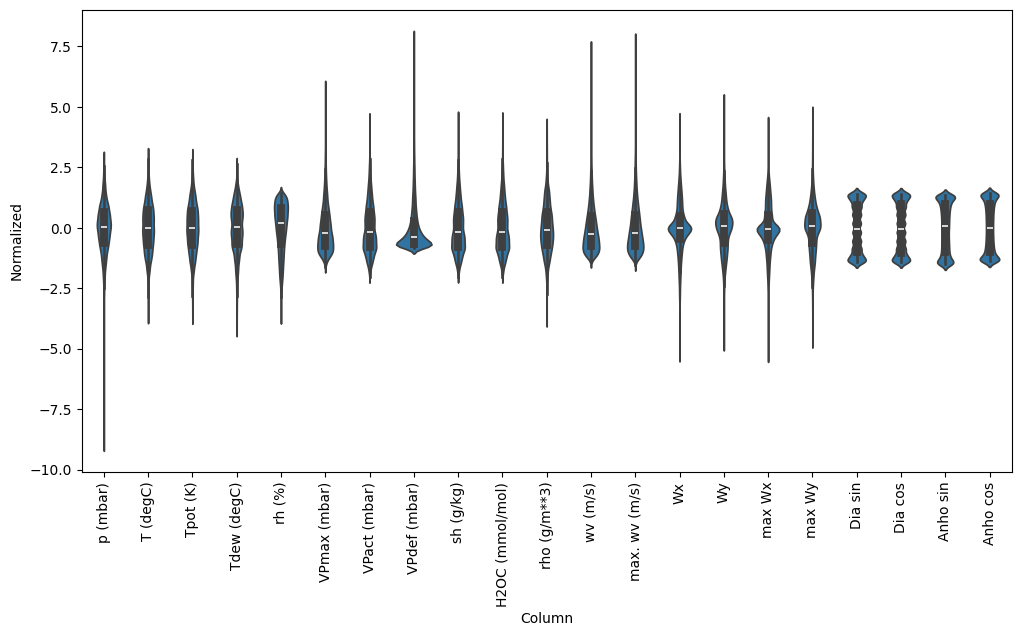

In [19]:
df_std = train_df.melt(var_name='Column', value_name='Normalized')                                                          # Transforma el DataFrame de formato ancho a formato largo para facilitar la graficación
plt.figure(figsize=(12, 6))                                                                                                # Define las dimensiones del lienzo o figura donde se dibujará la gráfica
ax = sns.violinplot(x='Column', y='Normalized', data=df_std)                                                                # Dibuja los diagramas de violín para observar la distribución y escala de cada columna
_ = ax.set_xticklabels(df.keys(), rotation=90)                                                                              # Configura las etiquetas del eje X con los nombres de las columnas rotados 90 grados

## Ventana de datos

Los modelos de esta práctica harán un conjunto de predicciones basadas en una ventana de muestras consecutivas de los datos. La agrupación de los datos se determinará mediante 3 parámetros:

1. **Anchura de la entrada (input_width):** Es el número de datos de diferentes tiempos que vamos a meter en el modelo.
1. **Anchura de la salida (label_width):** Es el número de datos de diferentes tiempos que vamos a tratar de predecir.
1. **Retardo de la salida (offset):** Es el tiempo a pasar entre el último dato de la entrada y el primero de la salida.

Aquí podemos ver una serie de distintos ejemplos:

`input_width = 5, label_width = 1, offset = 1`

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab9/im%C3%A1genes/ventana1.png?raw=1" alt="Ventana de ejemplo 1" width="400"/>


`input_width = 24, label_width = 4, offset = 0`

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab9/im%C3%A1genes/ventana2.png?raw=1" alt="Ventana de ejemplo 2" width="400"/>


El objetivo de esta parte es **crear una función que divida el dataset de entrada en todos los segmentos posibles de entrada/salida**, teniendo en cuenta los 3 parámetros mencionados anteriormente.

In [ ]:
# TODO: completa la función sliding_window, sustituyendo las partes en que se indica None
def sliding_window(data, labels, input_width, label_width=1, offset=1):
    x = []
    y = []

    for i in range(None):
        _x = data[i:None]
        _y = labels[None]
        x.append(_x)
        y.append(_y)

    x, y = np.array(x),np.array(y)

    if len(x.shape) == 2:
        x = x[:,:,np.newaxis]

    if len(y.shape) == 2:
        y = y[:,:,np.newaxis]

    return x, y


# Prueba el código
prueba_x, prueba_y = sliding_window(np.arange(5), np.arange(5), input_width=3, label_width=2, offset=-2)
print((prueba_x, prueba_y)) # La salida esperada es (array([[[0], [1], [2]], [[1], [2], [3]], [[2], [3], [4]]]), array([[[1], [2]], [[2], [3]], [[3], [4]]]))
assert(prueba_x.shape == (3, 3, 1) and prueba_y.shape == (3, 2, 1))

Una vez creada la función, se la pasamos a nuestros datos. Primero, definimos los parámetros de la función.

In [ ]:
input_width = 24
label_width = 24
offset = -input_width + 1
target_labels = 'T (degC)' # Vamos a tratar de predecir la temperatura


# TODO: Llama a la función para dividir el dataset
x_train, y_train = None
x_val, y_val = None
x_test, y_test = None

Vamos a comprobar el tamaño de los datos.

In [ ]:
print('x_train shape :', x_train.shape)
print('y_train shape :', y_train.shape)

x_train shape : (49017, 24, 19)
y_train shape : (49017, 24, 1)


## Creando el modelo

Una vez obtenido un correcto preprocesado de los datos, vamos a crear el modelo. En `torch` tenemos implementado tanto las capas recurrentes [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) y [LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html). Además, también es posible crear cualquier capa recurrente que queramos utilizando el módulo [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html).

Nuestro primer modelo constará de dos partes:

1. Capa recurrente ([LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html))
1. Capa densa, para adecuar la salida al tamaño esperado.

El módulo LSTM nos devuelve una salida para cada entrada:

![](https://drive.google.com/uc?export=view&id=17SYlF1UqHdCTTxZangKABGEwd_Mse44p)

Esto es útil para:
  * Apilamiento de capas RNN.
  * Entrenamiento de un modelo en múltiples pasos de tiempo simultáneamente.

En nuestro caso, aprovechamos una secuencia larga para supervisar las predicciones del modelo en cada momento. Para ello, hemos elegido las etiquetas de manera que se solapen con las entradas, tal como se muestra en el diagrama. La salida de nuestro modelo debe ser tan ancha como el número de pasos temporales contenidos en nuestras etiquetas (en este caso 24).

In [ ]:
# TODO: Completa el modelo con las partes necesarias
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = ...# Capa recurrente (usa un número de unidades de la capa oculta de 32).
        self.fc = ...# Capa lineal

    def forward(self, x):
        out, _ = self.lstm(x)      # out: [batch, time, 32]
        out = self.fc(out)         # [batch, time, 1]
        return out

lstm_model = LSTMModel(input_size=x_train.shape[-1])

## Entrenando el modelo

Por último, sólo nos queda entrenar el modelo durante 20 iteraciones. Haz *early stopping* para que pare el entrenamiento si el resultado en validación no mejora pasadas una serie de iteraciones.

In [ ]:
import torch.optim as optim
import torch.utils.data as data

MAX_EPOCHS = 20
batch_size = 32
loss_fn = nn.MSELoss()
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
patience = 5
# TODO - Crea los DataLoaders necesarios y realiza el entrenamiento con early stopping

Epoch 1/20 - Train loss: 0.0269
	Val loss: 0.0063
Epoch 2/20 - Train loss: 0.0063
	Val loss: 0.0058
Epoch 3/20 - Train loss: 0.0059
	Val loss: 0.0056
Epoch 4/20 - Train loss: 0.0057
	Val loss: 0.0057
Epoch 5/20 - Train loss: 0.0056
	Val loss: 0.0055
Epoch 6/20 - Train loss: 0.0055
	Val loss: 0.0055
Epoch 7/20 - Train loss: 0.0054
	Val loss: 0.0055
Epoch 8/20 - Train loss: 0.0054
	Val loss: 0.0055
Epoch 9/20 - Train loss: 0.0053


### Visualizando el resultado

Una vez entrenado el modelo, vamos a ver cómo hace la predicción en test, con respecto al resultado esperado.

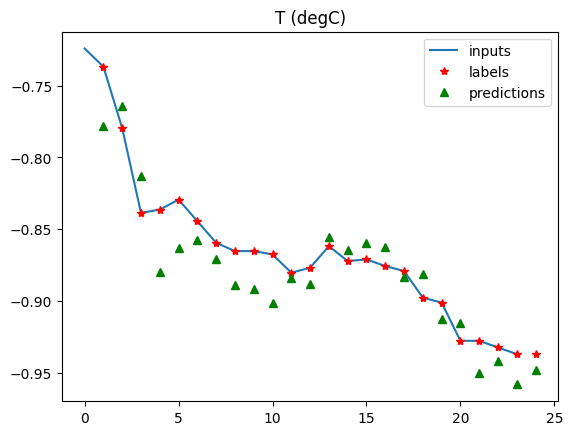

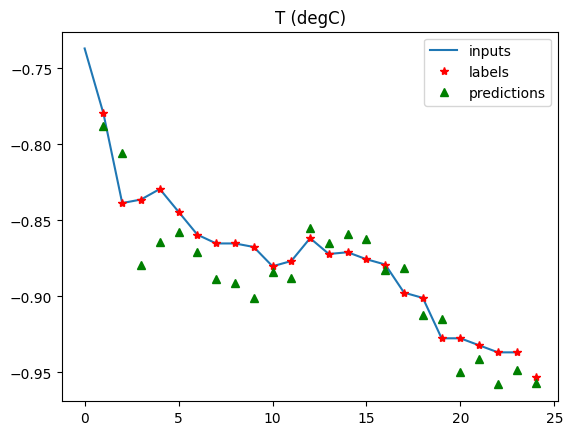

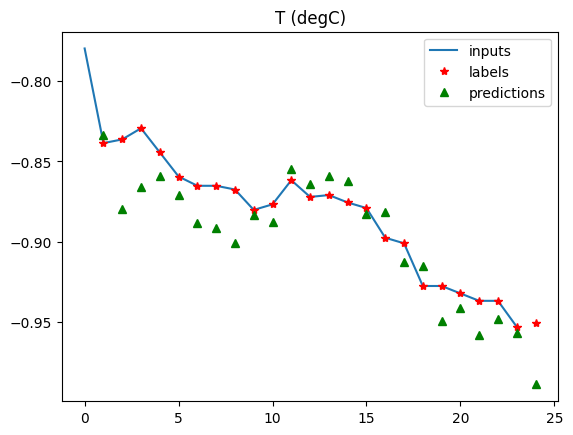

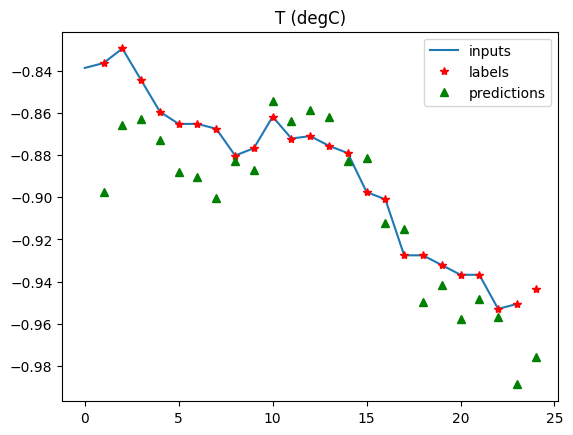

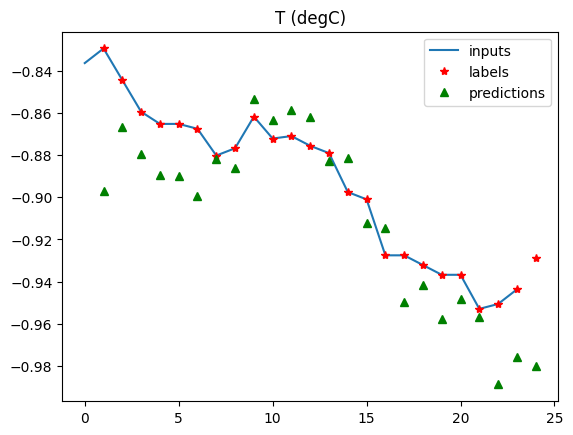

In [ ]:
def plot_prediction(feed_data, expected_result, model_result, target_label, offset=1, index=0):
    f_data_x = np.arange(feed_data.shape[1])
    e_data_x = np.arange(expected_result.shape[1]) + offset
    plt.plot(f_data_x, feed_data[index])
    plt.plot(e_data_x, expected_result[index], '*r')
    plt.plot(e_data_x, model_result[index], '^g')
    plt.legend(['inputs', 'labels', 'predictions'])
    plt.title(target_label)
    plt.show()

# TODO: Coge un lote de test y haz la predicción con el modelo
test_batch = ...
x_test_b, y_test_b = test_batch
x_test_b = x_test_b.to(device)
y_test_b = y_test_b.to(device)
model_result = ...

target_index = test_df.columns.get_loc(target_labels)

for i in range(5):
  # TODO: llama a la función plot_prediction con los parámetros correctos (reemplaza los None)
  plot_prediction(x_test_b[:, :, target_index].detach().cpu(),
                  None,
                  None,
                  target_labels,
                  label_width + offset,
                  index=i)

La predicción es bastante cercana...pero algo falla. Fíjate en el eje de las Y; ¡eso no las temperaturas! **¡Las temperaturas están mostrando el resultado estandarizado!** Revierte la normalización para un correcto visualizado.

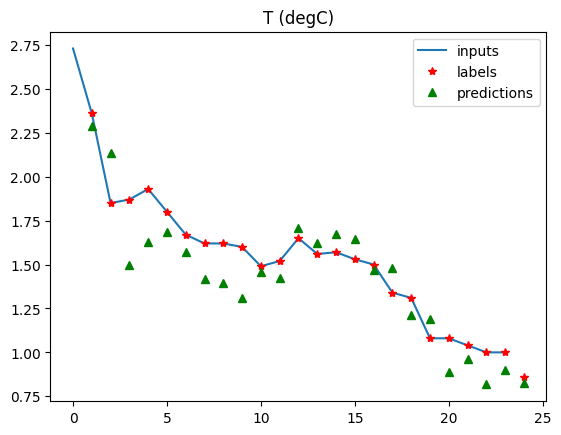

In [ ]:
# TODO: llama a la función plot_prediction con los valores sin estandarizar

¡Enhorabuena! Has creado tu primera red recursiva. Ahora vamos a hacerlo un poco más complejo.

# Predicción de múltiples pasos a futuro

El modelo que vimos anteriormente utiliza la salida de cada entrada del LSTM para predecir el tiempo siguiente, es decir, solo predice un valor que no tuviese como entrada (los otros 23 se usan solo para supervisar al modelo).

**¿Qué pasaría entonces si uso el mismo modelo para predecir la temperatura en las 24h siguientes?** Como nuestro modelo espera tener siempre datos de la hora anterior a la predicha, tendríamos que ir utilizando las predicciones anteriores como entradas para hacer cada predicción siguiente, lo que se conoce como un modelo autoregresivo.

$$
pred_{24} = model(x_0,...,x_{23})\\
pred_{25} = model(x_1,...,x_{23},pred_{24})\\
...\\
pred_{47} = model(x_{23},pred_{24},...,pred_{46})
$$

Esto requeriría hacer 24 llamadas al modelo. Para evitar ese gasto computacional, cambiaremos nuestro modelo para que devuelva las predicciones de las 24h siguientes. Esto también mejorará las predicciones del modelo, porque durante el entrenamiento cada predicción informará a todas las celdas del LSTM, ya que todas están por detrás de ella. Esto hará que las predicciones del modelo a largo plazo sean mejores que utilizando el método autoregresivo.

En primer lugar, definamos las ventanas de manera que las etiquetas se correspondan con las 24h siguientes a las suministradas como entrada.

In [ ]:
input_width = 24
label_width = 24
offset = 0
target_labels = 'T (degC)' # Vamos a tratar de predecir la temperatura


# TODO: Llama a la función para hacer el ventaneo
x_train, y_train = ...
x_val, y_val = ...
x_test, y_test = ...

train_loader = ...
val_loader = ...
test_loader = ...

## Creando el modelo

En este modelo vamos a necesitar acumular la información de las 24h de entrada para empezar a predecir los resultados a la salida. El esquema a seguir es el siguiente:

![](https://drive.google.com/uc?export=view&id=1R1tGHuXo2yueWlNyP1tWfgQLM6YP1xPw)

Para dar mayor capacidad al modelo, vamos a concatenar dos capas LSTM. La segunda capa tomará como entrada la salida de la primera, que tiene tantas componentes como haya en la entrada (ver diagrama del apartado *Creando el modelo*). La red lineal de predicción solo tomará como entrada la última salida de la segunda capa LSTM, como se muestra en el diagrama de esta celda.

In [ ]:
import torch
import torch.nn as nn

class StackedLSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm1 = ...# Capa recurrente (usa un número de unidades de la capa oculta de 32)
        self.lstm2 = ...# Capa recurrente (usa un número de unidades de la capa oculta de 32)
        self.fc = ...# Capa densa (escoge correctamente su número de unidades,
                  # ya que se necesita una unidad por cada característica de salida que queramos predecir,
                  # y por el número de veces que necesitamos predecir esa característica)
        self.reshape = lambda x: x.unsqueeze(-1)  # reorganizamos la salida para que tenga shape (label_width, n_output_features)

    def forward(self, x):
        # TODO - Completa la función
        # Asegúrate de que la parte densa de la red toma solo la última salida del LSTM
        ...
        out = ...
        return out

lstm_model = StackedLSTMModel(input_size=x_train.shape[-1])

## Entrenando el modelo

Por último, sólo nos queda entrenar el modelo durante 20 iteraciones.

In [ ]:
# TODO - Haz el entrenamiento del modelo

Epoch 1/20 - Train loss: 0.1154
	Val loss: 0.0819
Epoch 2/20 - Train loss: 0.0719
	Val loss: 0.0782
Epoch 3/20 - Train loss: 0.0675
	Val loss: 0.0753
Epoch 4/20 - Train loss: 0.0644
	Val loss: 0.0786
Epoch 5/20 - Train loss: 0.0618
	Val loss: 0.0775
Epoch 6/20 - Train loss: 0.0595
	Val loss: 0.0777
Epoch 7/20 - Train loss: 0.0576
	Val loss: 0.0802
Epoch 8/20 - Train loss: 0.0556


### Visualizando el resultado

Una vez entrenado el modelo, vamos a ver cómo hace la predicción en test, con respecto al resultado esperado.

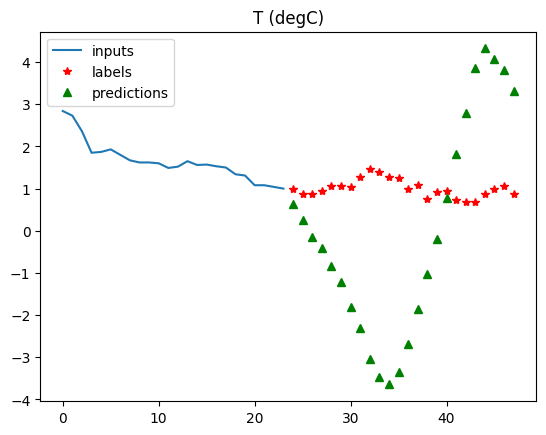

In [ ]:
# TODO: Coge un lote de test y haz la predicción con el modelo
plot_prediction(...)

Como puedes ver y es de esperar, es muchísimo más difícil hacer predicciones con mucha antelación.

# ¡ENHORABUENA! Has completado la práctica de Redes recurrentes.

# ¿Deseas saber más?

Puedes profundizar en las redes que utilizan como datos de entradas las mismas predicciones de la red en tiempos anteriores. Son las llamadas [redes auto-regresivas](https://eigenfoo.xyz/deep-autoregressive-models/).

# Trabajo extra

Como trabajo extra, se propone realizar una idea parecida, pero con dificultad añadida.

- Se utilizará una capa [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) en lugar de la LSTM.
- Se propone predecir todas las variables del dataset al mismo tiempo, en lugar de sólo la temperatura.

In [ ]:
# TODO: escribe el código para el trabajo extra sin ayuda. Usa todos los bloques de código que quieras.